# 08 — Data preprocessing (Bab 5.1)

Input: data bersih `/datalake/processed/` (237,978 rekaman). Output di zona **`/datalake/ml/`**:

| Tabel | Isi |
|---|---|
| `ml/traces` | 1 baris per rekaman: kunci, label, split, bobot kelas, waktu mulai, sensor |
| `ml/waveforms_z150s` | 1 baris per rekaman: komponen Z detik 0–150 (15,000 angka float32) yang sudah dinormalisasi z-score |

Langkah (bukti tiap langkah ada di notebook 07):

| # | Langkah | Alasan singkat |
|---|---|---|
| 1 | Gabung 3 dataset jadi 1 tabel; kolom dari 11 kolom bersama | Model belajar 4 kelas sekaligus; hanya kolom yang ada di semua dataset yang adil |
| 2 | Buang rekaman dengan Z kosong | Tidak ada sinyal untuk dibaca |
| 3 | Ambil komponen Z, detik 0–150 | E/N sering kosong; 0–150 s memuat 100% awal kejadian |
| 4 | Normalisasi z-score per rekaman | Besar counts ditentukan sensor & jarak, bukan kelas |
| 5 | Split acak 70/15/15 per rekaman | Data latih, validasi, uji terpisah |
| 6 | Bobot kelas dari data latih | Kelas kecil tetap dihitung penting |

In [1]:
import sys, os, time
sys.path.insert(0, os.path.abspath('../src'))
from common import *
import ml_prep as mp
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pyspark.sql import functions as F, Window

pd.set_option('display.width', 200, 'display.max_columns', 30)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
spark = spark_session('a2_preprocessing')
spark.sparkContext.addPyFile(os.path.abspath('../src/ml_prep.py'))
meta = spark.read.parquet(f'{HDFS}{PROCESSED}/metadata')
wf = spark.read.parquet(f'{HDFS}{PROCESSED}/waveforms')

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/09 10:33:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/09 10:33:23 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in mesos/standalone/kubernetes and LOCAL_DIRS in YARN).


Zona `ml` diberi hak akses yang sama dengan `processed` (Bab 3.1): engineer baca-tulis, scientist baca saja.

In [2]:
sh(f'hdfs dfs -mkdir -p {ML}')
sh(f'hdfs dfs -chgrp engineer {ML} && hdfs dfs -chmod 770 {ML}')
sh(f'hdfs dfs -setfacl -m group:scientist:r-x,default:group:engineer:rwx,default:group:scientist:r-x,default:other::--- {ML}')
sh(f'hdfs dfs -getfacl {ML}');

$ hdfs dfs -mkdir -p /datalake/ml



$ hdfs dfs -chgrp engineer /datalake/ml && hdfs dfs -chmod 770 /datalake/ml



$ hdfs dfs -setfacl -m group:scientist:r-x,default:group:engineer:rwx,default:group:scientist:r-x,default:other::--- /datalake/ml



$ hdfs dfs -getfacl /datalake/ml
# file: /datalake/ml
# owner: axelnakata
# group: engineer
user::rwx
group::rwx
group:scientist:r-x
mask::rwx
other::---
default:user::rwx
default:group::rwx
default:group:engineer:rwx
default:group:scientist:r-x
default:mask::rwx
default:other::---


## 1. Satu tabel dan pemilihan kolom
Ketiga dataset sudah digabung di A1 (`processed/metadata`, kolom `dataset`). Fitur dari CSV **hanya boleh berasal dari 11 kolom yang ada di ketiga dataset**. Kolom yang hanya ada di sebagian dataset (26 kolom) tidak dipakai sama sekali, termasuk waktu tiba P dan `event_id`.

In [3]:
raw_cols = {d: spark.read.csv(f'{HDFS}{RAW}/{d}/{d}_metadata.csv', header=True).columns for d in DATASETS}
shared = [c for c in raw_cols['comcat'] if all(c in raw_cols[d] for d in DATASETS)]
ROLE = {
    'source_type': ('dipakai', 'label (versi bersih A1: kolom `label`)'),
    'trace_name': ('dipakai', 'kunci ke waveform'),
    'trace_start_time': ('dipakai', 'fitur waktu: jam, hari, hari dalam tahun (notebook 09)'),
    'station_channel_code': ('dipakai', 'fitur jenis sensor EH/BH/HH (notebook 09)'),
    'station_network_code': ('disimpan', 'hanya untuk graph analytics Bab 6, bukan fitur'),
    'station_code': ('disimpan', 'hanya untuk graph analytics Bab 6, bukan fitur'),
    'station_latitude_deg': ('dibuang', 'lokasi: 41 stasiun hanya merekam 1 kelas'),
    'station_longitude_deg': ('dibuang', 'lokasi: 41 stasiun hanya merekam 1 kelas'),
    'station_elevation_m': ('dibuang', 'lokasi: 41 stasiun hanya merekam 1 kelas'),
    'station_location_code': ('dibuang', 'lokasi: posisi sensor di dalam stasiun'),
    'trace_sampling_rate_hz': ('dibuang', 'selalu 100 Hz, tidak membawa informasi'),
}
assert sorted(shared) == sorted(ROLE)
cols = pd.DataFrame([(c, *ROLE[c]) for c in shared], columns=['column', 'decision', 'reason'])
save_md(cols, 'a2_column_decisions', '11 kolom CSV yang ada di ketiga dataset dan perannya')
others = [c for c in raw_cols['comcat'] if c not in shared]
print(f'{len(shared)} kolom bersama, {len(others)} kolom lain tidak dipakai: {others}')
cols

11 kolom bersama, 26 kolom lain tidak dipakai: ['event_id', 'source_origin_time', 'source_latitude_deg', 'source_longitude_deg', 'source_depth_km', 'preferred_source_magnitude', 'preferred_source_magnitude_type', 'preferred_source_magnitude_uncertainty', 'source_depth_uncertainty_km', 'source_horizontal_uncertainty_km', 'trace_S_arrival_sample', 'trace_P_arrival_sample', 'trace_S_arrival_uncertainty_s', 'trace_P_arrival_uncertainty_s', 'trace_P_polarity', 'trace_S_onset', 'trace_P_onset', 'trace_snr_db', 'source_type_pnsn_label', 'source_local_magnitude', 'source_local_magnitude_uncertainty', 'source_duration_magnitude', 'source_duration_magnitude_uncertainty', 'source_hand_magnitude', 'trace_missing_channel', 'trace_has_offset']


,column,decision,reason
0,source_type,dipakai,label (versi bersih A1: kolom `label`)
1,station_network_code,disimpan,"hanya untuk graph analytics Bab 6, bukan fitur"
2,station_channel_code,dipakai,fitur jenis sensor EH/BH/HH (notebook 09)
3,station_code,disimpan,"hanya untuk graph analytics Bab 6, bukan fitur"
4,station_location_code,dibuang,lokasi: posisi sensor di dalam stasiun
5,station_latitude_deg,dibuang,lokasi: 41 stasiun hanya merekam 1 kelas
6,station_longitude_deg,dibuang,lokasi: 41 stasiun hanya merekam 1 kelas
7,station_elevation_m,dibuang,lokasi: 41 stasiun hanya merekam 1 kelas
8,trace_name,dipakai,kunci ke waveform
9,trace_sampling_rate_hz,dibuang,"selalu 100 Hz, tidak membawa informasi"


## 2. Tabel ML dan split acak 70/15/15
Split per rekaman memakai `hash(dataset + trace_name) mod 100`: 0–69 train, 70–84 val, 85–99 test. Hash membuat hasilnya **acak tapi sama setiap kali dijalankan**, dan bisa dihitung paralel tanpa mengumpulkan data ke satu mesin.

In [4]:
h = F.pmod(F.xxhash64('dataset', 'trace_name'), F.lit(100))
tab = (meta.select('dataset', 'trace_name', 'label', 'trace_start_time', 'station_channel_code', 'station_network_code', 'station_code')
       .withColumn('split', F.when(h < 70, 'train').when(h < 85, 'val').otherwise('test')))

## 3. Potong Z 0–150 s + normalisasi z-score (Spark, seluruh rekaman)
Untuk setiap rekaman, `ml_prep.standardize(z)`:
1. ambil **komponen Z, sampel 0–14,999** (detik 0–150);
2. **z-score**: `(x − rata-rata) / standar deviasi` → rata-rata 0, std 1;
3. kalau Z datar (semua nol) → rekaman dibuang.

Spark membaca hanya kolom `z` dari 66.5 GB Parquet, mengerjakannya di 10 core sekaligus, dan menulis hasilnya ke HDFS.

In [5]:
spark.conf.set('spark.sql.execution.arrow.maxRecordsPerBatch', 256)
SCHEMA = 'dataset string, trace_name string, label string, z array<float>, split string'

def cut(batches):
    for b in batches:
        rows = [(d, t, l, w, s) for d, t, l, z, s in zip(b.dataset, b.trace_name, b.label, b.z, b.split)
                if (w := mp.standardize(z)) is not None]
        yield pd.DataFrame(rows, columns=['dataset', 'trace_name', 'label', 'z', 'split'])

t0 = time.time()
(wf.select('dataset', 'trace_name', 'z')
   .join(F.broadcast(tab.select('dataset', 'trace_name', 'label', 'split')), ['dataset', 'trace_name'])
   .mapInPandas(cut, SCHEMA)
   .coalesce(100)
   .write.mode('overwrite').partitionBy('split').parquet(f'{HDFS}{ML}/waveforms_z150s'))
print(f'selesai dalam {time.time() - t0:.0f} detik')
sh(f'hdfs dfs -du -s -h {ML}/waveforms_z150s');

selesai dalam 106 detik


$ hdfs dfs -du -s -h /datalake/ml/waveforms_z150s
13.1 G  13.1 G  /datalake/ml/waveforms_z150s


In [6]:
win = spark.read.parquet(f'{HDFS}{ML}/waveforms_z150s')
tab = tab.join(win.select('dataset', 'trace_name'), ['dataset', 'trace_name'])
before = meta.groupBy('label').count().toPandas().set_index('label')['count']
after = tab.groupBy('label').count().toPandas().set_index('label')['count']
fun = pd.DataFrame({'awal (data bersih A1)': before, 'dibuang: Z kosong': before - after, 'akhir': after}).loc[CLASSES].T
fun['total'] = fun.sum(axis=1)
save_md(fun.reset_index(names='step'), 'a2_preprocessing_funnel', 'Jumlah rekaman sebelum dan sesudah preprocessing')
fun

label,earthquake,explosion,surface_event,noise,total
awal (data bersih A1),162700,16139,8912,50227,237978
dibuang: Z kosong,3303,208,0,0,3511
akhir,159397,15931,8912,50227,234467


## 4. Bobot kelas
Rumus: **bobot kelas = jumlah data latih ÷ (jumlah kelas × jumlah data latih kelas itu)**. Kelas besar mendapat bobot < 1, kelas kecil > 1. Hasil kali jumlah × bobot sama untuk semua kelas, jadi total pengaruh setiap kelas saat training sama.

In [7]:
n_train = tab.filter("split = 'train'").groupBy('label').count().toPandas().set_index('label')['count'].loc[CLASSES]
weights = (n_train.sum() / (len(CLASSES) * n_train)).round(4)
wt = pd.DataFrame({'n_train': n_train, 'rumus': [f'{n_train.sum():,} / (4 × {n:,})' for n in n_train],
                   'class_weight': weights, 'n_train × weight': (n_train * weights).round(0)})
save_md(wt.reset_index(names='label'), 'a2_class_weights', 'Bobot kelas = N_train / (4 × n_kelas)')
w_map = F.create_map([F.lit(x) for kv in weights.items() for x in kv])
tab = tab.withColumn('class_weight', w_map[F.col('label')])
tab.coalesce(1).write.mode('overwrite').parquet(f'{HDFS}{ML}/traces')
traces = spark.read.parquet(f'{HDFS}{ML}/traces')
wt

,n_train,rumus,class_weight,n_train × weight
label,,,,
earthquake,111545,"164,048 / (4 × 111,545)",0.3677,41015.0
explosion,11136,"164,048 / (4 × 11,136)",3.6828,41012.0
surface_event,6175,"164,048 / (4 × 6,175)",6.6416,41012.0
noise,35192,"164,048 / (4 × 35,192)",1.1654,41013.0


## 5. Hasil split dan pemeriksaan

234,467 rekaman, semua panjang 15000 sampel, tanpa NaN


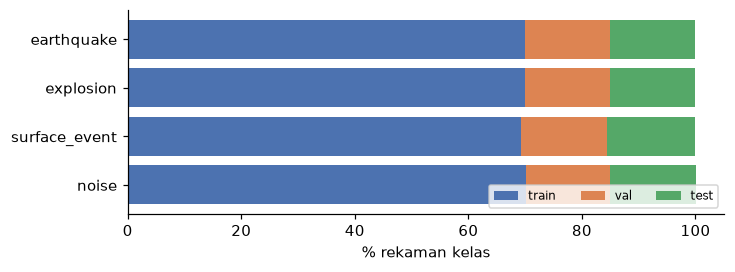

split,train,val,test,total,train_pct,val_pct,test_pct
label,,,,,,,
earthquake,111545,23915,23937,159397,70.0,15.0,15.0
explosion,11136,2388,2407,15931,69.9,15.0,15.1
surface_event,6175,1356,1381,8912,69.3,15.2,15.5
noise,35192,7419,7616,50227,70.1,14.8,15.2


In [8]:
sp = traces.groupBy('label', 'split').count().toPandas().pivot(index='label', columns='split', values='count').loc[CLASSES, ['train', 'val', 'test']]
sp['total'] = sp.sum(axis=1)
pct = (100 * sp[['train', 'val', 'test']].div(sp.total, axis=0)).round(1).add_suffix('_pct')
split_tab = pd.concat([sp, pct], axis=1)
save_md(split_tab.reset_index(), 'a2_split_by_class', 'Jumlah rekaman per kelas dan split (acak per rekaman)')

chk = win.select(F.size('z').alias('n'), F.expr('exists(z, x -> isnan(x))').alias('nan')).groupBy('n', 'nan').count().collect()
assert len(chk) == 1 and chk[0].n == mp.N and not chk[0].nan
assert traces.count() == win.count() == traces.select('dataset', 'trace_name').distinct().count()
print(f'{win.count():,} rekaman, semua panjang {chk[0].n} sampel, tanpa NaN')

fig, ax = plt.subplots(figsize=(7, 2.4))
left = np.zeros(len(CLASSES))
for s, col in zip(['train', 'val', 'test'], ['#4c72b0', '#dd8452', '#55a868']):
    ax.barh(CLASSES[::-1], pct[f'{s}_pct'][::-1], left=left, color=col, label=s)
    left += pct[f'{s}_pct'][::-1].values
ax.set_xlabel('% rekaman kelas'); ax.legend(ncols=3, fontsize=8, loc='lower right')
save_fig('a2_split_by_class'); plt.show()
split_tab

Setiap kelas terbagi ±70/15/15, semua rekaman punya panjang 15,000 sampel, dan tidak ada nilai NaN.

## 6. Normalisasi z-score: contoh sebelum vs sesudah (4 kelas)
Rumus: **`x_baru = (x − rata-rata) / std`**, dihitung per rekaman (detik 0–150).
- Rata-rata = posisi "nol" sinyal (offset sensor). Dikurangi → sinyal bergetar di sekitar 0.
- Std ≈ "besar getaran rata-rata". Dibagi → satuan berubah dari *counts* menjadi "berapa kali getaran rata-rata".
- Contoh: [−300, 100, 400, −200] counts → rata-rata 0, std ≈ 274 → [−1.10, 0.37, 1.46, −0.73].
- Bentuk sinyal **tidak berubah**, hanya skalanya. Kenapa bukan min–max? Min–max membagi dengan nilai terbesar, jadi satu lonjakan tunggal bisa menekan seluruh sinyal mendekati nol. Std memakai semua 15,000 angka sehingga lebih stabil.

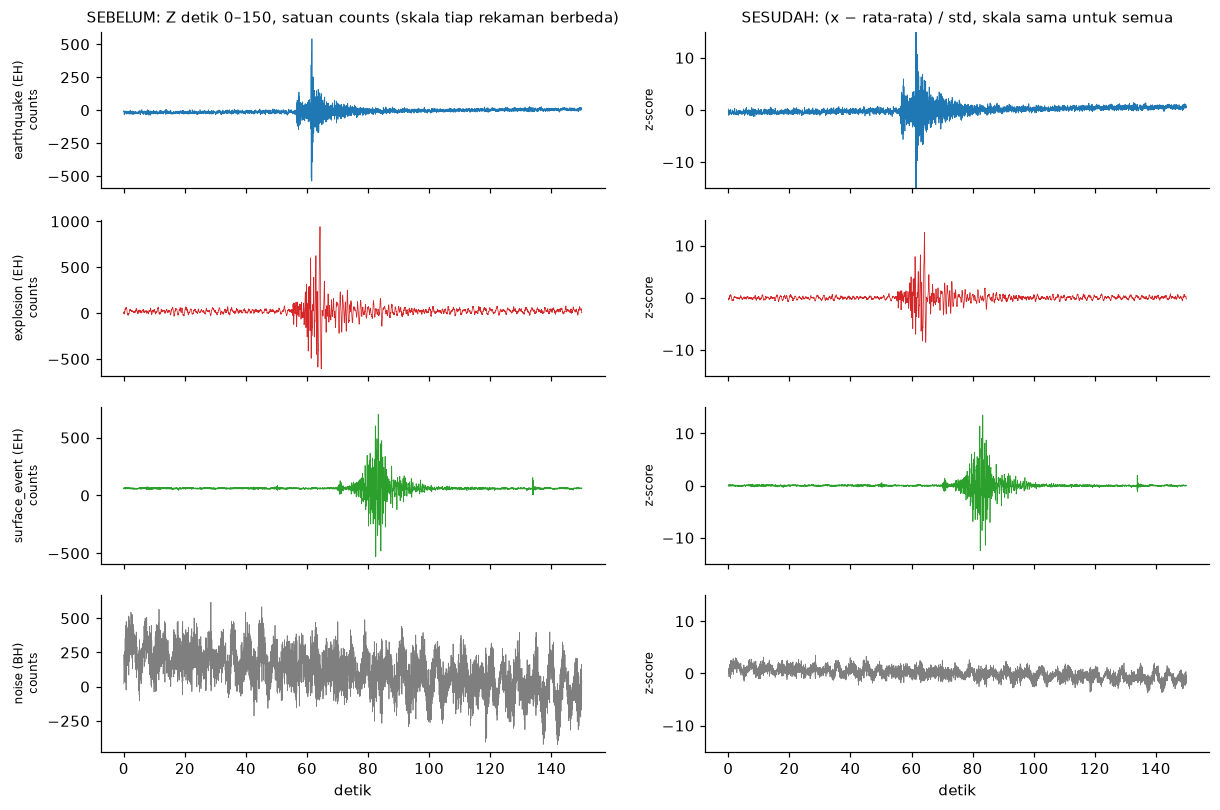

,sensor,rata2_sebelum,std_sebelum,puncak_sebelum,rata2_sesudah,std_sesudah,puncak_sesudah
label,,,,,,,
earthquake,EH,-7.66,24.46,541.71,-0.0,1.0,22.46
explosion,EH,21.62,73.67,943.33,0.0,1.0,12.51
surface_event,EH,61.39,47.33,701.01,0.0,1.0,13.51
noise,BH,112.68,144.23,617.37,0.0,1.0,3.71


In [9]:
demo = (traces.filter("split = 'train'").join(meta.select('dataset', 'trace_name', 'snr_z'), ['dataset', 'trace_name'])
        .filter("label = 'noise' OR snr_z BETWEEN 15 AND 25")
        .withColumn('r', F.row_number().over(Window.partitionBy('label').orderBy('trace_name'))).filter('r = 1')
        .select('dataset', 'trace_name', 'label', 'station_channel_code'))
raw_z = (wf.join(F.broadcast(demo), ['dataset', 'trace_name']).select('label', 'station_channel_code', 'z')
         .toPandas().set_index('label').loc[CLASSES])
new_z = (win.join(F.broadcast(demo.select('dataset', 'trace_name')), ['dataset', 'trace_name']).select('label', 'z')
         .toPandas().set_index('label').loc[CLASSES])

fig, axes = plt.subplots(4, 2, figsize=(13, 8.5), sharex=True)
t = np.arange(mp.N) / 100
for i, c in enumerate(CLASSES):
    z = np.asarray(raw_z.loc[c, 'z'])[:mp.N]
    axes[i, 0].plot(t, z, color=COLORS[c], lw=.5)
    axes[i, 0].set_ylabel(f'{c} ({raw_z.loc[c, "station_channel_code"]})\ncounts', fontsize=8)
    axes[i, 1].plot(t, new_z.loc[c, 'z'], color=COLORS[c], lw=.5)
    axes[i, 1].set_ylim(-15, 15); axes[i, 1].set_ylabel('z-score', fontsize=8)
axes[0, 0].set_title('SEBELUM: Z detik 0–150, satuan counts (skala tiap rekaman berbeda)', fontsize=10)
axes[0, 1].set_title('SESUDAH: (x − rata-rata) / std, skala sama untuk semua', fontsize=10)
axes[3, 0].set_xlabel('detik'); axes[3, 1].set_xlabel('detik')
save_fig('a2_normalization_4class'); plt.show()

norm_tab = pd.DataFrame({
    'sensor': raw_z.station_channel_code,
    'rata2_sebelum': [np.asarray(z)[:mp.N].mean() for z in raw_z.z],
    'std_sebelum': [np.asarray(z)[:mp.N].std() for z in raw_z.z],
    'puncak_sebelum': [np.abs(np.asarray(z)[:mp.N]).max() for z in raw_z.z],
    'rata2_sesudah': [np.asarray(z).mean() for z in new_z.z],
    'std_sesudah': [np.asarray(z).std() for z in new_z.z],
    'puncak_sesudah': [np.abs(np.asarray(z)).max() for z in new_z.z]}).round(2)
save_md(norm_tab.reset_index(), 'a2_normalization_example', 'Contoh normalisasi z-score: sebelum vs sesudah')
norm_tab

- **Sebelum:** setiap rekaman punya offset dan skala sendiri (lihat sumbu y kiri dan kolom `rata2_sebelum`).
- **Sesudah:** semua rekaman punya rata-rata 0 dan std 1, dengan sumbu y yang sama. Yang tersisa hanya **bentuk**: kejadian tenang lalu melonjak, sedangkan noise bergetar merata tanpa lonjakan.
- Sinyal **tidak difilter**: gelombang lambat pada noise tetap ada, dan CNN yang belajar memisahkannya (notebook 09).

In [10]:
spark.stop()